In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones (en semanas) se adjunta. El jefe de proyecto sólo puede hacer seguimiento estrecho de cuatro actividades.

In [4]:
pregunta_1 = "1. Calcule el calendario del proyecto con sus holguras.  "
pregunta_2 = "2. Ordene las actividades de mayor a menor necesidad de vigilancia (primero las críticas; entre las demás, menor holgura total primero y, a igualdad, menor holgura libre). ¿Cuáles son las cuatro elegidas?  "
pregunta_3 = "3. ¿Qué actividades *no críticas* no pueden retrasarse ni una semana sin obligar a mover alguna sucesora? ¿Por qué no son críticas si no admiten retraso?  "
pregunta_4 = "4. ¿Qué actividad puede retrasarse más semanas sin que nadie lo note? ¿Cuántas?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule el calendario del proyecto con sus holguras.  

2. Ordene las actividades de mayor a menor necesidad de vigilancia (primero las críticas; entre las demás, menor holgura total primero y, a igualdad, menor holgura libre). ¿Cuáles son las cuatro elegidas?  

3. ¿Qué actividades *no críticas* no pueden retrasarse ni una semana sin obligar a mover alguna sucesora? ¿Por qué no son críticas si no admiten retraso?  

4. ¿Qué actividad puede retrasarse más semanas sin que nadie lo note? ¿Cuántas?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 6       ),
    ('B'     , '---'      , 3       ),
    ('C'     , '---'      , 2       ),
    ('D'     , 'B'        , 4       ),
    ('E'     , 'B'        , 8       ),
    ('F'     , 'A,B,C'    , 7       ),
    ('G'     , 'D,F'      , 8       ),
    ('H'     , 'G'        , 7       ),
    ('I'     , 'E'        , 6       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,6
B,---,3
C,---,2
D,B,4
E,B,8
F,"A,B,C",7
G,"D,F",8
H,G,7
I,E,6


El proyecto corresponde a la apertura de una clínica veterinaria; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Estudio de mercado y local',
    'B': 'Proyecto de reforma y licencia',
    'C': 'Obra de reforma',
    'D': 'Instalación de quirófano y radiología',
    'E': 'Mobiliario y equipamiento clínico',
    'F': 'Software de gestión',
    'G': 'Selección de personal',
    'H': 'Acuerdos con proveedores',
    'I': 'Registro sanitario',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de mercado y local
B,Proyecto de reforma y licencia
C,Obra de reforma
D,Instalación de quirófano y radiología
E,Mobiliario y equipamiento clínico
F,Software de gestión
G,Selección de personal
H,Acuerdos con proveedores
I,Registro sanitario


# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Calcule el calendario del proyecto con sus holguras.  

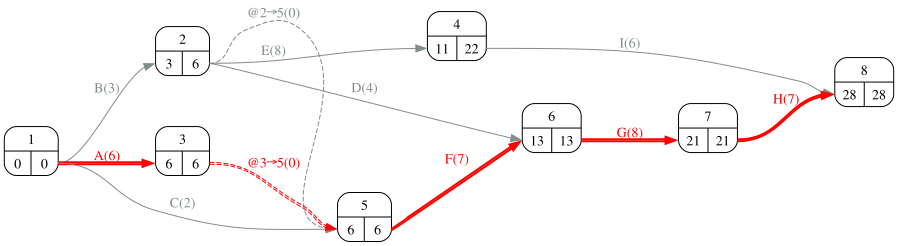

In [9]:
#| fig-cap: "Grafo PERT con tiempos y camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [10]:
#| tbl-cap: "Calendario y holguras"
#| label: tbl-calendario
calendario = proyecto.calendar(datos_proyecto['duration'])
calendario

,inicio_mas_temprano,inicio_mas_tardio,fin_mas_temprano,fin_mas_tardio,H_libre,H_independiente,H_total,duracion
activity,,,,,,,,
A,0,0,6,6,0,0,0,6
B,0,3,3,6,0,0,3,3
C,0,4,2,6,4,4,4,2
D,3,9,7,13,6,3,6,4
E,3,14,11,22,0,0,11,8
F,6,6,13,13,0,0,0,7
G,13,13,21,21,0,0,0,8
H,21,21,28,28,0,0,0,7
I,11,22,17,28,11,0,11,6


Con los números sustituidos, actividad a actividad (ES, EF, LS y LF son inicio y fin más tempranos y más tardíos; «pred.» y «suc.» las predecesoras y sucesoras inmediatas):

In [11]:
#| tbl-cap: "Cálculo paso a paso de fechas y holguras"
#| label: tbl-holgurasPaso
detalle_holguras(calendario, prelaciones)

,ES = máx EF pred.,EF = ES + d,LF = mín LS suc.,LS = LF − d,H_total = LS − ES,H_libre = mín ES suc. − EF,"H_indep. = máx(0, mín ES suc. − máx LF pred. − d)"
actividad,,,,,,,
A,inicial → 0,0 + 6 = 6,mín(F: 6) = 6,6 − 6 = 0,0 − 0 = 0,6 − 6 = 0,"máx(0, 6 − 0 − 6) = 0"
B,inicial → 0,0 + 3 = 3,"mín(D: 9, E: 14, F: 6) = 6",6 − 3 = 3,3 − 0 = 3,3 − 3 = 0,"máx(0, 3 − 0 − 3) = 0"
C,inicial → 0,0 + 2 = 2,mín(F: 6) = 6,6 − 2 = 4,4 − 0 = 4,6 − 2 = 4,"máx(0, 6 − 0 − 2) = 4"
D,máx(B: 3) = 3,3 + 4 = 7,mín(G: 13) = 13,13 − 4 = 9,9 − 3 = 6,13 − 7 = 6,"máx(0, 13 − 6 − 4) = 3"
E,máx(B: 3) = 3,3 + 8 = 11,mín(I: 22) = 22,22 − 8 = 14,14 − 3 = 11,11 − 11 = 0,"máx(0, 11 − 6 − 8) = 0"
F,"máx(A: 6, B: 3, C: 2) = 6",6 + 7 = 13,mín(G: 13) = 13,13 − 7 = 6,6 − 6 = 0,13 − 13 = 0,"máx(0, 13 − 6 − 7) = 0"
G,"máx(D: 7, F: 13) = 13",13 + 8 = 21,mín(H: 21) = 21,21 − 8 = 13,13 − 13 = 0,21 − 21 = 0,"máx(0, 21 − 13 − 8) = 0"
H,máx(G: 21) = 21,21 + 7 = 28,final → 28,28 − 7 = 21,21 − 21 = 0,28 (fin) − 28 = 0,"máx(0, 28 − 21 − 7) = 0"
I,máx(E: 11) = 11,11 + 6 = 17,final → 28,28 − 6 = 22,22 − 11 = 11,28 (fin) − 17 = 11,"máx(0, 28 − 22 − 6) = 0"


## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. Ordene las actividades de mayor a menor necesidad de vigilancia (primero las críticas; entre las demás, menor holgura total primero y, a igualdad, menor holgura libre). ¿Cuáles son las cuatro elegidas?  

In [13]:
#| tbl-cap: "Actividades ordenadas por necesidad de vigilancia"
#| label: tbl-orden
orden = calendario.sort_values(['H_total', 'H_libre', 'duracion'], ascending=[True, True, False])
orden['prioridad'] = range(1, len(orden) + 1)
orden[['prioridad', 'H_total', 'H_libre', 'H_independiente', 'duracion']]

,prioridad,H_total,H_libre,H_independiente,duracion
activity,,,,,
G,1,0,0,0,8
F,2,0,0,0,7
H,3,0,0,0,7
A,4,0,0,0,6
B,5,3,0,0,3
C,6,4,4,4,2
D,7,6,6,3,4
E,8,11,0,0,8
I,9,11,11,0,6


In [14]:
Markdown(f'Las cuatro actividades a vigilar son **{", ".join(orden.index[:4])}**. '
         'Si hay más de cuatro críticas, el criterio de desempate es la duración (una actividad larga tiene más ocasiones de retrasarse).')

Las cuatro actividades a vigilar son **G, F, H, A**. Si hay más de cuatro críticas, el criterio de desempate es la duración (una actividad larga tiene más ocasiones de retrasarse).

## Apartado 3

In [15]:
display(Markdown(pregunta_3))

3. ¿Qué actividades *no críticas* no pueden retrasarse ni una semana sin obligar a mover alguna sucesora? ¿Por qué no son críticas si no admiten retraso?  

In [16]:
sin_margen = calendario.index[(calendario['H_total'] > 0) & (calendario['H_libre'] == 0)].tolist()
Markdown(f'''Las actividades {", ".join(sin_margen)} tienen holgura libre cero pero holgura total positiva: cualquier retraso suyo mueve el inicio más temprano de una sucesora, pero esa sucesora tiene margen suficiente para absorberlo sin que el proyecto se alargue. No son críticas porque el plazo no depende de ellas; lo que no admiten es retrasarse sin molestar.''')

Las actividades B, E tienen holgura libre cero pero holgura total positiva: cualquier retraso suyo mueve el inicio más temprano de una sucesora, pero esa sucesora tiene margen suficiente para absorberlo sin que el proyecto se alargue. No son críticas porque el plazo no depende de ellas; lo que no admiten es retrasarse sin molestar.

## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. ¿Qué actividad puede retrasarse más semanas sin que nadie lo note? ¿Cuántas?  

In [18]:
mas_libre = calendario['H_libre'].idxmax()
Markdown(f'{mas_libre} puede retrasarse hasta {int(calendario.loc[mas_libre, "H_libre"])} semanas sin mover a ninguna otra actividad ni al plazo (su holgura libre).')

I puede retrasarse hasta 11 semanas sin mover a ninguna otra actividad ni al plazo (su holgura libre).